
# Análise Bioestatística — Kidney Disease Dataset

**Disciplina:** Introdução à Bioestatística

**Objetivo:** Investigar a associação entre sete parâmetros relacionados à análise de urina e a classificação de doença renal crônica, por meio de análises estatísticas e testes de hipóteses.

**Fonte dos dados:** [Kaggle — Kidney Disease Dataset](https://www.kaggle.com/datasets/akshayksingh/kidney-disease-dataset)


In [1]:
# Bibliotecas que usaremos para analisar e manipular os dados
import pandas as pd
import numpy as np

# Bibliotecas para vizualização gráfica
import matplotlib.pyplot as plt
import seaborn as sns

# Ferramentas para análise estatística
from scipy import stats

In [2]:
!pip install -q kagglehub

In [3]:

# Importando dependências
import kagglehub
from glob import glob
import pandas as pd


# Baixando os arquivos
file_path = kagglehub.dataset_download("akshayksingh/kidney-disease-dataset")

# A maior parte dos datasets contém um único arquivo no formato CSV.
# Estamos assumindo que há apenas um arquivo. Vamos listar os arquivos com o glob
# e importar o primeiro arquivo CSV
files_from_ds = glob(f'{file_path}/*.csv')
print(f'CSV files found: {files_from_ds}')

# Carregando o arquivo CSV como um dataframe do Pandas
df = pd.read_csv(files_from_ds[0])
df


Using Colab cache for faster access to the 'kidney-disease-dataset' dataset.
CSV files found: ['/kaggle/input/kidney-disease-dataset/kidney_disease.csv']


,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,395,55.0,80.0,1.020,0.0,0.0,normal,normal,notpresent,notpresent,...,47,6700,4.9,no,no,no,good,no,no,notckd
396,396,42.0,70.0,1.025,0.0,0.0,normal,normal,notpresent,notpresent,...,54,7800,6.2,no,no,no,good,no,no,notckd
397,397,12.0,80.0,1.020,0.0,0.0,normal,normal,notpresent,notpresent,...,49,6600,5.4,no,no,no,good,no,no,notckd
398,398,17.0,60.0,1.025,0.0,0.0,normal,normal,notpresent,notpresent,...,51,7200,5.9,no,no,no,good,no,no,notckd


In [4]:
# Verificando as informações gerais do dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 26 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              400 non-null    int64  
 1   age             391 non-null    float64
 2   bp              388 non-null    float64
 3   sg              353 non-null    float64
 4   al              354 non-null    float64
 5   su              351 non-null    float64
 6   rbc             248 non-null    object 
 7   pc              335 non-null    object 
 8   pcc             396 non-null    object 
 9   ba              396 non-null    object 
 10  bgr             356 non-null    float64
 11  bu              381 non-null    float64
 12  sc              383 non-null    float64
 13  sod             313 non-null    float64
 14  pot             312 non-null    float64
 15  hemo            348 non-null    float64
 16  pcv             330 non-null    object 
 17  wc              295 non-null    obj

In [5]:
#selecionando a coluna da albumina e contando quantas vezes cada valor aparece
df['al'].value_counts(dropna=False).sort_index()

,count
al,
0.0,199
1.0,44
2.0,43
3.0,43
4.0,24
5.0,1
NaN,46


### Exploração da variável albumina (`al`)

A variável `al` apresenta níveis de 0 a 5. Na análise inicial, observou-se que o nível 0 foi o mais frequente, aparecendo em 199 pacientes. Também foram identificados 46 valores ausentes, correspondendo a 11,5% das observações.

Essa análise permitiu conhecer a distribuição geral da variável, mas ainda não permite comparar os pacientes com e sem doença renal crônica.

In [6]:
pd.crosstab(df['al'], df['classification'], margins=True)

classification,ckd,ckd\t,notckd,All
al,,,,
0.0,54,0,145,199
1.0,44,0,0,44
2.0,42,1,0,43
3.0,43,0,0,43
4.0,24,0,0,24
5.0,1,0,0,1
All,208,1,145,354


In [7]:
df['classification'].unique()

array(['ckd', 'ckd\t', 'notckd'], dtype=object)

In [8]:
# removendo espaços e caracteres de tabulação na início e no final dos textos
df['classification'] = df['classification'].str.strip()

In [9]:
pd.crosstab(df['al'], df['classification'], margins=True)

classification,ckd,notckd,All
al,,,
0.0,54,145,199
1.0,44,0,44
2.0,43,0,43
3.0,43,0,43
4.0,24,0,24
5.0,1,0,1
All,209,145,354


In [10]:
pd.crosstab(df['al'], df['classification'], normalize='columns') * 100

classification,ckd,notckd
al,,
0.0,25.837321,100.0
1.0,21.052632,0.0
2.0,20.574163,0.0
3.0,20.574163,0.0
4.0,11.483254,0.0
5.0,0.478469,0.0


In [11]:
df['su'].value_counts(dropna=False).sort_index()

,count
su,
0.0,290
1.0,13
2.0,18
3.0,14
4.0,13
5.0,3
NaN,49


In [12]:
pd.crosstab(df['su'], df['classification'], margins=True)

classification,ckd,notckd,All
su,,,
0.0,145,145,290
1.0,13,0,13
2.0,18,0,18
3.0,14,0,14
4.0,13,0,13
5.0,3,0,3
All,206,145,351


In [13]:
pd.crosstab(df['su'], df['classification'], normalize='columns') * 100

classification,ckd,notckd
su,,
0.0,70.388350,100.0
1.0,6.310680,0.0
2.0,8.737864,0.0
3.0,6.796117,0.0
4.0,6.310680,0.0
5.0,1.456311,0.0


In [14]:
df['rbc'].value_counts(dropna=False)

,count
rbc,
normal,201
NaN,152
abnormal,47


In [15]:
pd.crosstab(df['rbc'], df['classification'], margins=True)

classification,ckd,notckd,All
rbc,,,
abnormal,47,0,47
normal,60,141,201
All,107,141,248


In [16]:
pd.crosstab(df['rbc'], df['classification'], normalize='columns') * 100

classification,ckd,notckd
rbc,,
abnormal,43.925234,0.0
normal,56.074766,100.0


In [17]:
df['pc'].value_counts(dropna=False)

,count
pc,
normal,259
abnormal,76
NaN,65


In [18]:
pd.crosstab(df['pc'], df['classification'], margins=True)

classification,ckd,notckd,All
pc,,,
abnormal,76,0,76
normal,118,141,259
All,194,141,335


In [19]:
pd.crosstab(df['pc'], df['classification'], normalize='columns') * 100

classification,ckd,notckd
pc,,
abnormal,39.175258,0.0
normal,60.824742,100.0


In [20]:
df['pcc'].value_counts(dropna=False)

,count
pcc,
notpresent,354
present,42
NaN,4


In [21]:
pd.crosstab(df['pcc'], df['classification'], margins=True)

classification,ckd,notckd,All
pcc,,,
notpresent,208,146,354
present,42,0,42
All,250,146,396


In [22]:
df['classification'].unique()

array(['ckd', 'notckd'], dtype=object)

In [23]:
pd.crosstab(df['pcc'], df['classification'], normalize='columns') * 100

classification,ckd,notckd
pcc,,
notpresent,83.2,100.0
present,16.8,0.0


In [24]:
df['ba'].value_counts(dropna=False)

,count
ba,
notpresent,374
present,22
NaN,4


In [25]:
pd.crosstab(df['ba'], df['classification'], margins=True)

classification,ckd,notckd,All
ba,,,
notpresent,228,146,374
present,22,0,22
All,250,146,396


In [26]:
pd.crosstab(df['ba'], df['classification'], normalize='columns') * 100

classification,ckd,notckd
ba,,
notpresent,91.2,100.0
present,8.8,0.0


In [27]:
df['sg'].value_counts(dropna=False).sort_index()

,count
sg,
1.005,7
1.010,84
1.015,75
1.020,106
1.025,81
NaN,47


In [28]:
pd.crosstab(df['sg'], df['classification'], margins=True)

classification,ckd,notckd,All
sg,,,
1.005,7,0,7
1.01,84,0,84
1.015,75,0,75
1.02,31,75,106
1.025,11,70,81
All,208,145,353


In [29]:
pd.crosstab(df['sg'], df['classification'], normalize='columns') * 100

classification,ckd,notckd
sg,,
1.005,3.365385,0.000000
1.010,40.384615,0.000000
1.015,36.057692,0.000000
1.020,14.903846,51.724138
1.025,5.288462,48.275862


In [30]:
variaveis = ['sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba']

# Conferindo os tipos das variáveis
print("TIPOS DAS VARIÁVEIS:")
print(df[variaveis].dtypes)

# Conferindo os valores ausentes
print("\nVALORES AUSENTES:")
print(df[variaveis].isnull().sum())

# Conferindo os grupos
print("\nCLASSIFICAÇÃO DOS PACIENTES:")
print(df['classification'].value_counts())

TIPOS DAS VARIÁVEIS:
sg     float64
al     float64
su     float64
rbc     object
pc      object
pcc     object
ba      object
dtype: object

VALORES AUSENTES:
sg      47
al      46
su      49
rbc    152
pc      65
pcc      4
ba       4
dtype: int64

CLASSIFICAÇÃO DOS PACIENTES:
classification
ckd       250
notckd    150
Name: count, dtype: int64


In [31]:
from scipy.stats import chi2_contingency

variaveis = ['sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba']

for var in variaveis:
    tabela = pd.crosstab(df[var], df['classification'])

    qui2, p, gl, esperadas = chi2_contingency(tabela)

    print(f'\nVARIÁVEL: {var}')
    print(f'Menor frequência esperada: {esperadas.min():.2f}')
    print(f'Frequências esperadas menores que 5: {(esperadas < 5).sum()} de {esperadas.size}')


VARIÁVEL: sg
Menor frequência esperada: 2.88
Frequências esperadas menores que 5: 2 de 10

VARIÁVEL: al
Menor frequência esperada: 0.41
Frequências esperadas menores que 5: 2 de 12

VARIÁVEL: su
Menor frequência esperada: 1.24
Frequências esperadas menores que 5: 2 de 12

VARIÁVEL: rbc
Menor frequência esperada: 20.28
Frequências esperadas menores que 5: 0 de 4

VARIÁVEL: pc
Menor frequência esperada: 31.99
Frequências esperadas menores que 5: 0 de 4

VARIÁVEL: pcc
Menor frequência esperada: 15.48
Frequências esperadas menores que 5: 0 de 4

VARIÁVEL: ba
Menor frequência esperada: 8.11
Frequências esperadas menores que 5: 0 de 4


In [32]:
# Agrupar os níveis de albumina
df['al_agrupado'] = df['al'].apply(
    lambda x: '3 ou mais' if pd.notna(x) and x >= 3 else x
)

# Criar tabela de contingência
tabela_al = pd.crosstab(
    df['al_agrupado'],
    df['classification']
)

# Calcular frequências esperadas
qui2, p, gl, esperadas = chi2_contingency(tabela_al)

print("TABELA DE CONTINGÊNCIA:")
display(tabela_al)

print("\nFREQUÊNCIAS ESPERADAS:")
print(esperadas)

print("\nMenor frequência esperada:", esperadas.min())
print("Frequências menores que 5:", (esperadas < 5).sum(), "de", esperadas.size)

TABELA DE CONTINGÊNCIA:


classification,ckd,notckd
al_agrupado,,
0.0,54,145
1.0,44,0
2.0,43,0
3 ou mais,68,0



FREQUÊNCIAS ESPERADAS:
[[117.48870056  81.51129944]
 [ 25.97740113  18.02259887]
 [ 25.38700565  17.61299435]
 [ 40.14689266  27.85310734]]

Menor frequência esperada: 17.612994350282484
Frequências menores que 5: 0 de 8


In [33]:
variaveis = ['sg', 'al_agrupado', 'su', 'rbc', 'pc', 'pcc', 'ba']

resultados_qui2 = []

for var in variaveis:
    tabela = pd.crosstab(df[var], df['classification'])

    qui2, p, gl, esperadas = chi2_contingency(tabela)

    resultados_qui2.append({
        'Variável': var,
        'N': tabela.values.sum(),
        'Qui-quadrado': qui2,
        'Graus de liberdade': gl,
        'p-valor': p
    })

resultado_qui2 = pd.DataFrame(resultados_qui2)

display(resultado_qui2)

,Variável,N,Qui-quadrado,Graus de liberdade,p-valor
0,sg,353,223.101996,4,4.030570e-47
1,al_agrupado,354,191.294992,3,3.205272e-41
2,su,351,51.968447,5,5.475766e-10
3,rbc,248,73.583829,1,9.645164e-18
4,pc,335,69.229632,1,8.764136e-17
5,pcc,396,25.694777,1,3.999079e-07
6,ba,396,11.978282,1,5.382418e-04


# Teste de hipótese: Qui-quadrado de independência

Para investigar a associação entre os parâmetros urinários e a classificação dos pacientes quanto à presença de doença renal crônica (CKD), aplicamos o teste qui-quadrado de independência (χ²).

Foram realizadas sete análises, considerando as variáveis `sg`, `al_agrupado`, `su`, `rbc`, `pc`, `pcc` e `ba` em relação à variável `classification`.

A variável `al` foi agrupada em quatro categorias devido à baixa frequência observada em algumas das categorias originais. Esse agrupamento permitiu atender aos critérios de frequência esperada para a aplicação do teste.

Antes da aplicação dos testes, verificamos as frequências esperadas das tabelas de contingência. Adotamos como critério que nenhuma frequência esperada fosse inferior a 1 e que, no máximo, 20% das frequências esperadas fossem inferiores a 5.

As análises utilizaram as observações disponíveis para cada variável, desconsiderando os valores ausentes. Foi adotado um nível de significância de 5% (α = 0,05).

As hipóteses consideradas foram:

- H₀: não existe associação entre a variável analisada e a classificação dos pacientes.
- H₁: existe associação entre a variável analisada e a classificação dos pacientes.

Os resultados foram analisados por meio da estatística qui-quadrado, dos graus de liberdade e dos respectivos p-valores.

# Interpretação dos resultados de albumina, células de pus, aglomerados de células de pus e bactérias

**Albumina (al_agrupado)**: Foram analisadas 354 observações válidas. Entre os pacientes com doença renal crônica (CKD), 25,84% apresentaram nível 0 de albumina, enquanto os demais apresentaram níveis 1, 2, 3 ou mais. Já entre os pacientes sem a doença (notCKD), todas as observações válidas apresentaram nível 0. O teste qui-quadrado apresentou p-valor de 3,21 × 10⁻⁴¹, indicando associação estatisticamente significativa entre o nível de albumina e a classificação dos pacientes.

**Pus cells (pc)**: Foram observadas 335 respostas válidas. Entre os pacientes com CKD, 39,18% apresentaram células de pus anormais. Entre os pacientes sem a doença (notCKD), todas as observações válidas foram classificadas como normais. O teste qui-quadrado apresentou p-valor de 8,76 × 10⁻¹⁷, indicando associação estatisticamente significativa.

**Pus cell clumps (pcc)**: Das 396 observações válidas, 16,8% dos pacientes com CKD apresentaram presença de aglomerados de células de pus. Entre os pacientes sem CKD, não foram observados casos dessa condição. O teste qui-quadrado apresentou p-valor de 4,00 × 10⁻⁷, indicando associação estatisticamente significativa.

**Bacteria (ba)**: Foram analisadas 396 observações válidas. A presença de bactérias foi identificada em 8,8% dos pacientes com CKD, enquanto não foram observados casos entre os pacientes sem CKD. O teste qui-quadrado apresentou p-valor de 0,000538, também indicando associação estatisticamente significativa.

De modo geral, os resultados apontam associações estatisticamente significativas entre as quatro variáveis analisadas e a classificação dos pacientes, considerando o nível de significância de 5% (α = 0,05). Entretanto, esses resultados não permitem estabelecer relações de causalidade.

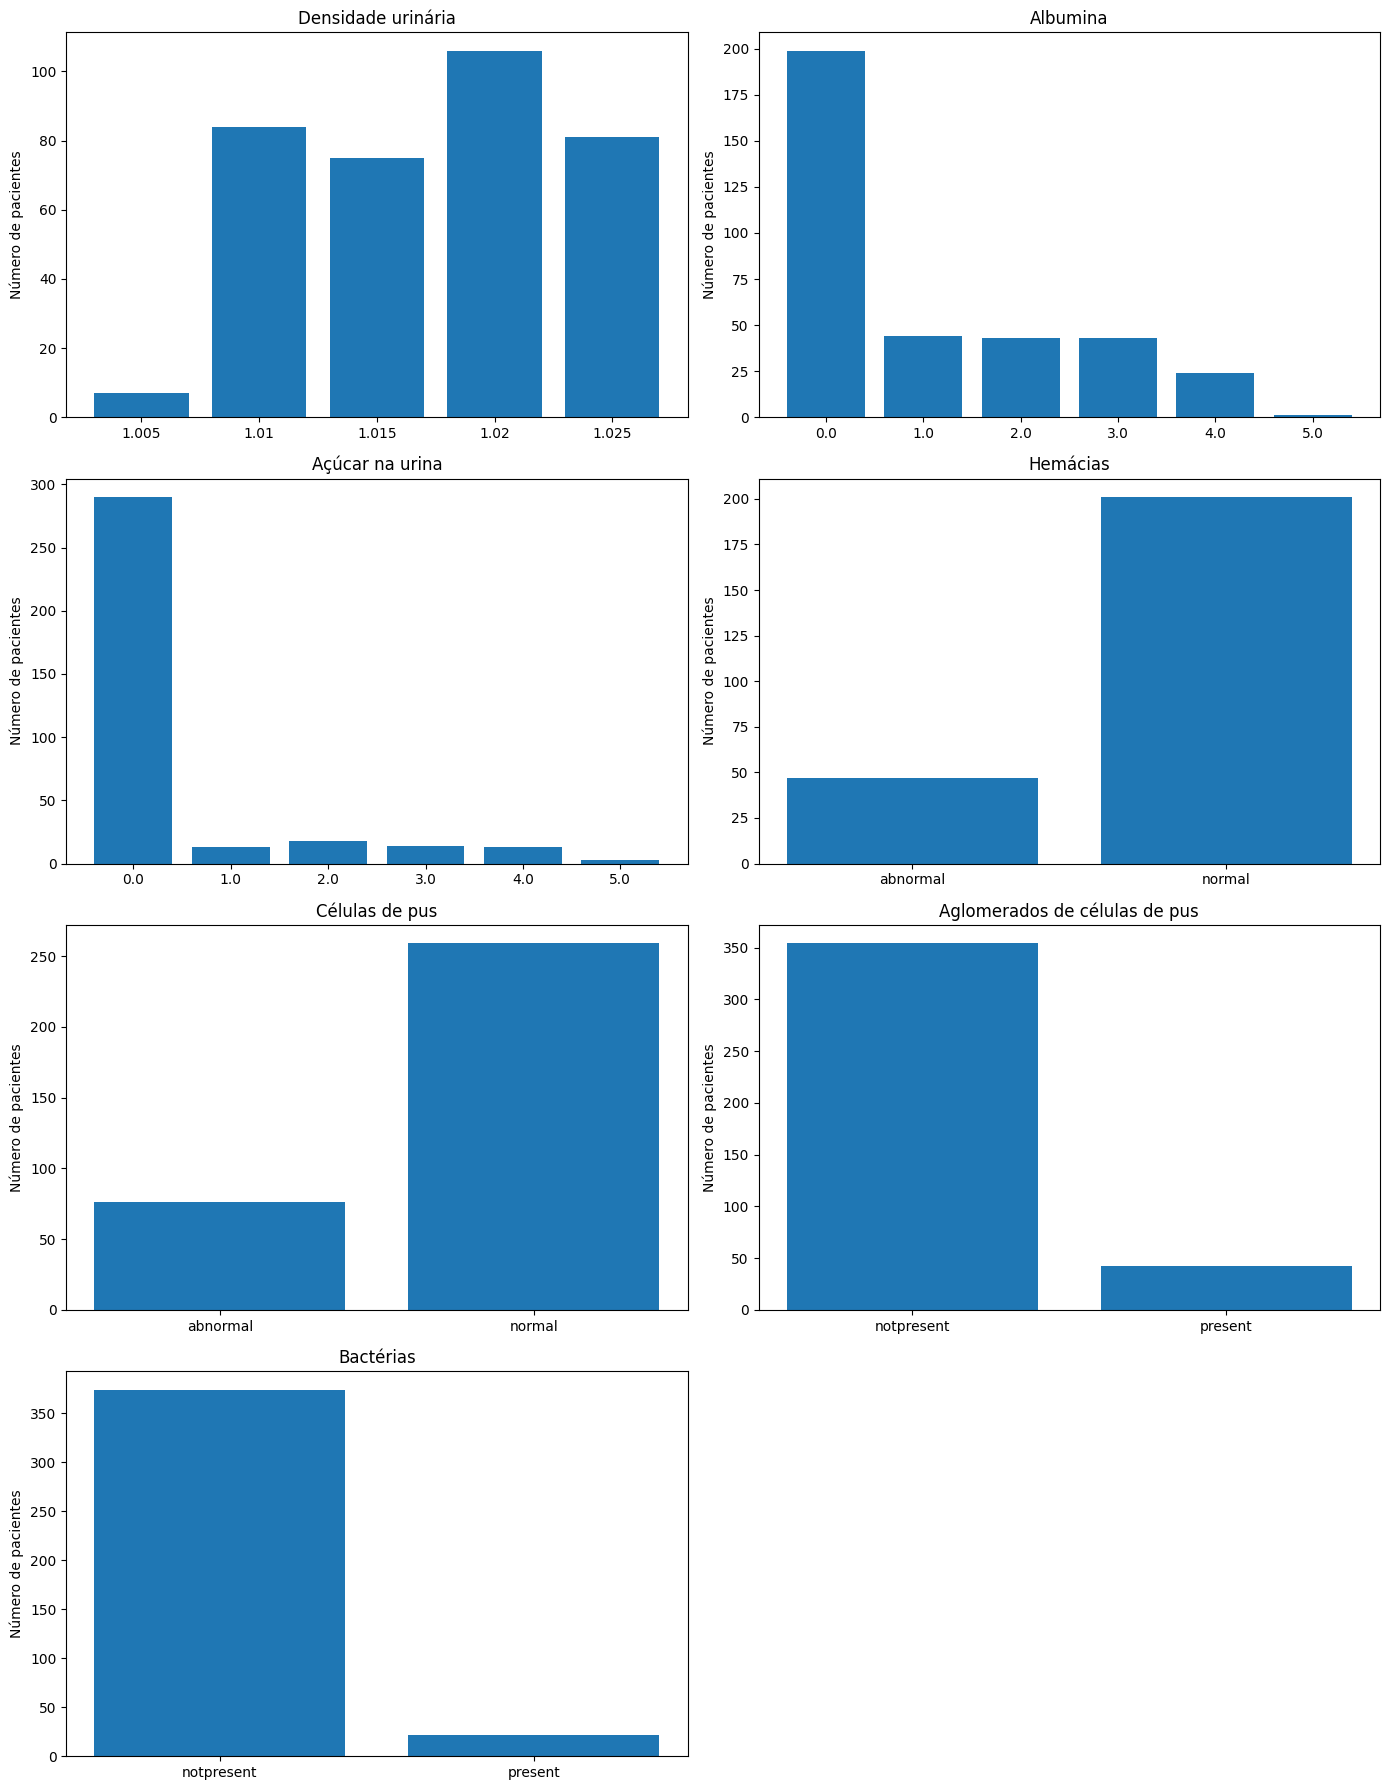

In [34]:
import matplotlib.pyplot as plt

variaveis = ['sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba']

nomes = {
    'sg': 'Densidade urinária',
    'al': 'Albumina',
    'su': 'Açúcar na urina',
    'rbc': 'Hemácias',
    'pc': 'Células de pus',
    'pcc': 'Aglomerados de células de pus',
    'ba': 'Bactérias'
}

fig, axes = plt.subplots(4, 2, figsize = (14, 18))
axes = axes.flatten()

for i, variavel in enumerate(variaveis):
  frequencias = df[variavel].dropna().value_counts().sort_index()

  axes[i].bar(frequencias.index.astype(str), frequencias.values)
  axes[i].set_title(nomes[variavel])
  axes[i].set_ylabel('Número de pacientes')
  axes[i].tick_params(axis='x', rotation=0)

axes[-1].axis('off')

plt.tight_layout()
plt.show()




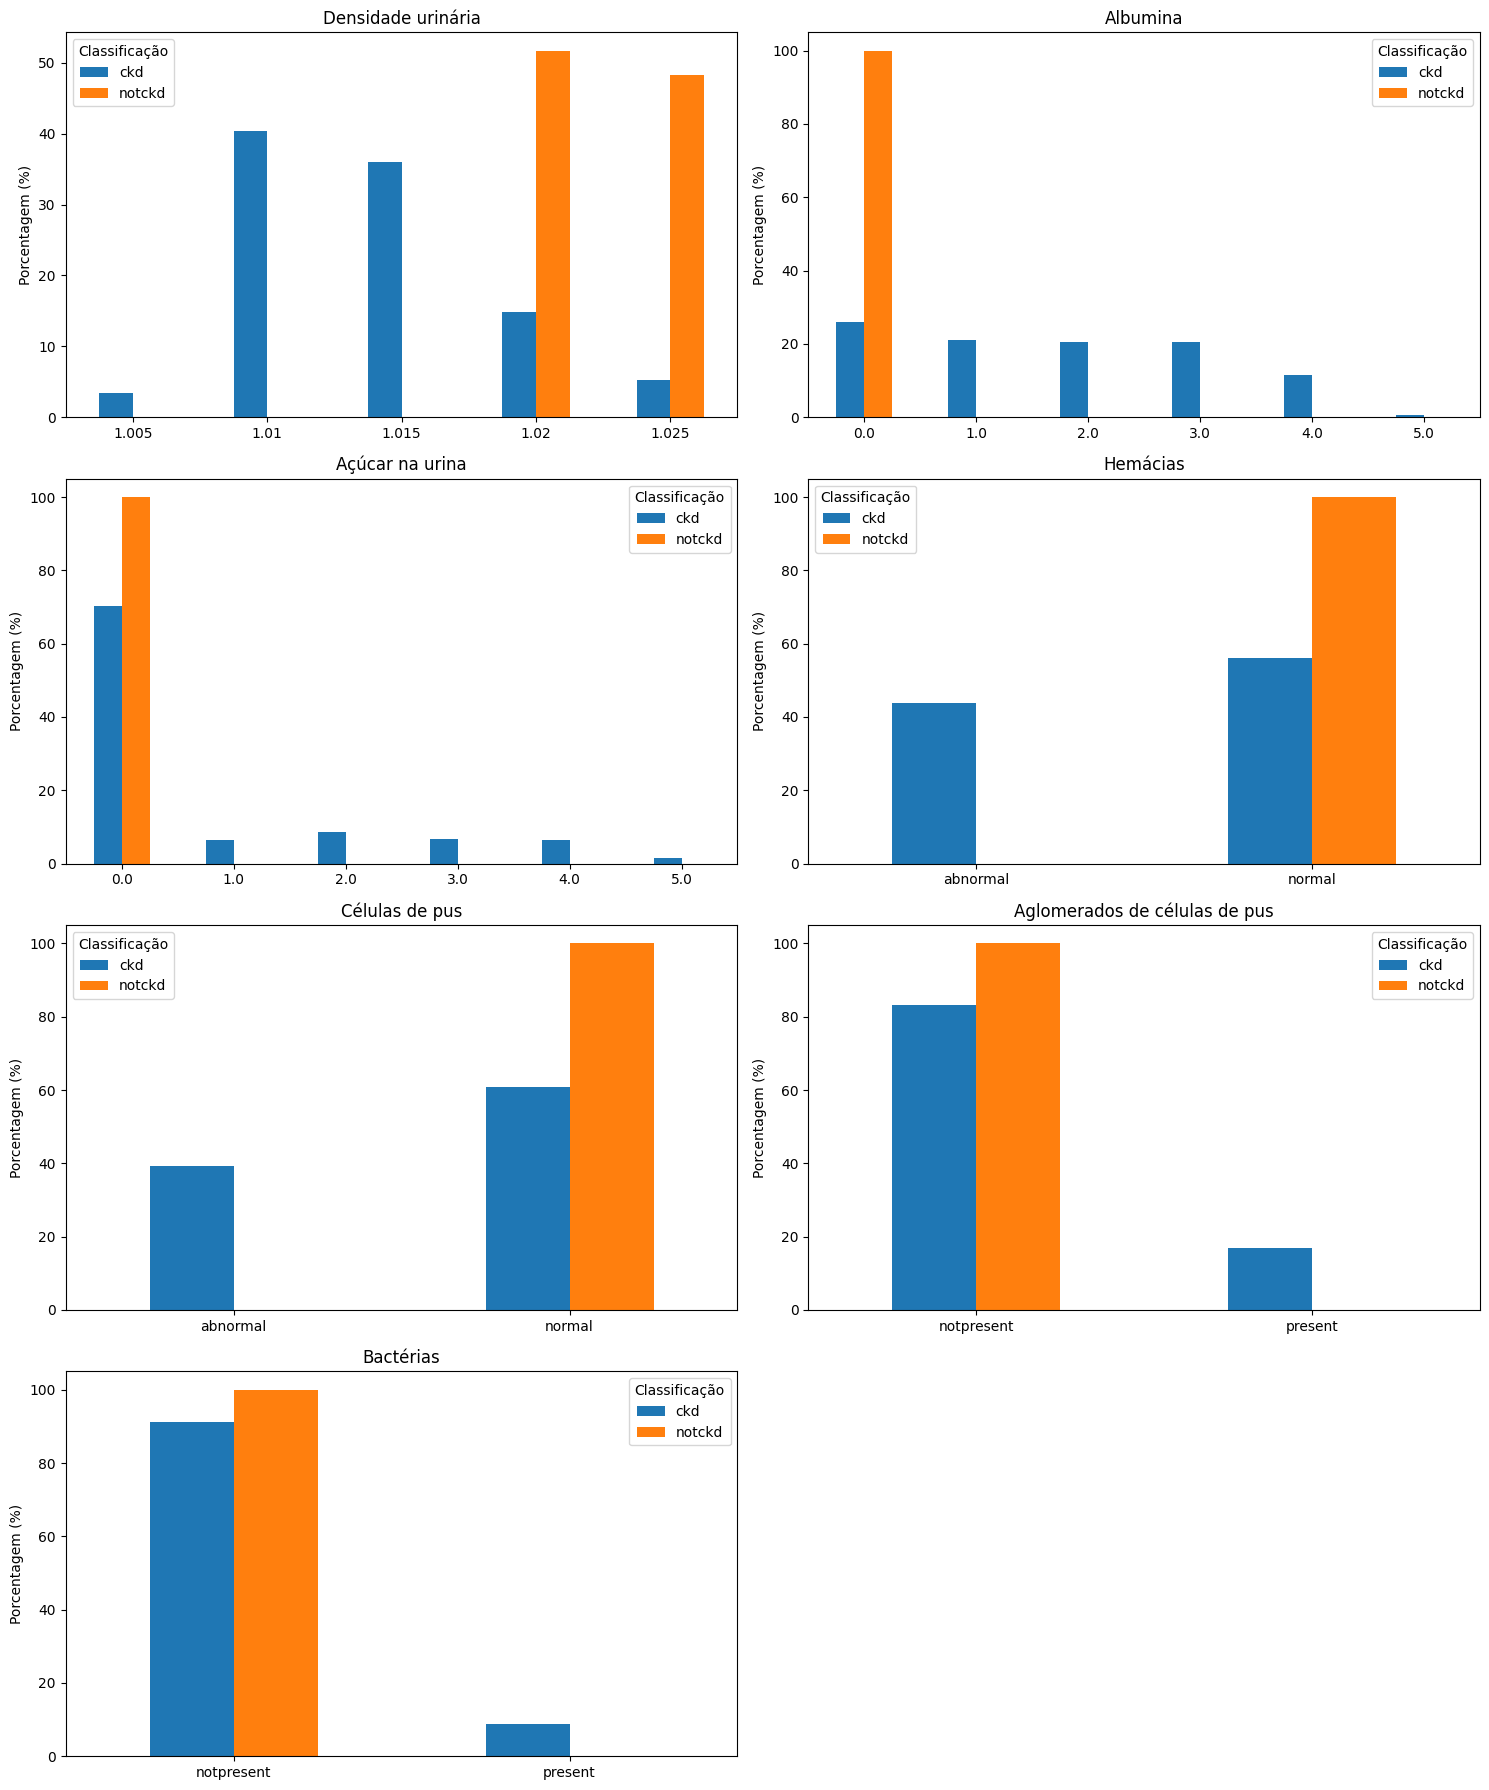

In [35]:

fig, axes = plt.subplots(4, 2, figsize=(15, 18))
axes = axes.flatten()

for i, variavel in enumerate(variaveis):
    tabela = pd.crosstab(
        df[variavel],
        df['classification'],
        normalize='columns'
    ) * 100

    tabela.plot(kind='bar', ax=axes[i])

    axes[i].set_title(nomes[variavel])
    axes[i].set_ylabel('Porcentagem (%)')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=0)
    axes[i].legend(title='Classificação')

axes[-1].axis('off')

plt.tight_layout()
plt.show()


## Interpretação dos gráficos

Os gráficos apresentam a distribuição percentual das sete variáveis urinárias (`sg`, `al`, `su`, `rbc`, `pc`, `pcc` e `ba`) de acordo com a classificação dos pacientes em CKD e notCKD. As porcentagens foram calculadas separadamente para cada grupo, permitindo comparar a distribuição das categorias entre os pacientes com e sem doença renal crônica.

### Densidade urinária (`sg`)

Observa-se uma diferença na distribuição da densidade urinária entre os grupos. Entre os pacientes com CKD, predominam as categorias 1.010 (40,38%) e 1.015 (36,06%). Já entre os pacientes sem CKD, foram observadas apenas as categorias 1.020 (51,72%) e 1.025 (48,28%). Essa diferença de distribuição foi estatisticamente significativa pelo teste qui-quadrado (p = 4,03 × 10⁻⁴⁷).

### Albumina (`al`)

Observa-se que todos os pacientes sem CKD apresentaram nível 0 de albumina. Entre os pacientes com CKD, apenas 25,84% apresentaram nível 0, enquanto os demais estavam distribuídos entre os níveis 1 e 5. Essa diferença indica uma associação estatisticamente significativa entre os níveis de albumina e a classificação dos pacientes (p = 3,21 × 10⁻⁴¹).

### Açúcar na urina (`su`)

Entre os pacientes sem CKD, todos apresentaram nível 0 de açúcar na urina. Já entre os pacientes com CKD, 70,39% apresentaram nível 0, enquanto os demais apresentaram níveis entre 1 e 5. Essa diferença na distribuição foi estatisticamente significativa (p = 5,48 × 10⁻¹⁰).

### Hemácias (`rbc`)

Entre os pacientes sem CKD, todos apresentaram hemácias em níveis normais. Já entre os pacientes com CKD, 43,93% apresentaram níveis anormais, enquanto 56,07% apresentaram níveis normais. Essa diferença na distribuição foi estatisticamente significativa (p = 9,65 × 10⁻¹⁸).

### Células de pus (`pc`)

Entre os pacientes sem CKD, todos apresentaram células de pus em níveis normais. Entre os pacientes com CKD, 39,18% apresentaram níveis anormais, enquanto 60,82% apresentaram níveis normais. Essa diferença na distribuição foi estatisticamente significativa (p = 8,76 × 10⁻¹⁷).

### Aglomerados de células de pus (`pcc`)

Entre os pacientes sem CKD, todos apresentaram ausência de aglomerados de células de pus. Entre os pacientes com CKD, 16,80% apresentaram essa característica, enquanto 83,20% não apresentaram. Essa diferença na distribuição foi estatisticamente significativa (p = 4,00 × 10⁻⁷).

### Bactérias (`ba`)

Entre os pacientes sem CKD, todos apresentaram ausência de bactérias na urina. Entre os pacientes com CKD, 8,80% apresentaram presença de bactérias, enquanto 91,20% não apresentaram. Essa diferença na distribuição foi estatisticamente significativa (p = 5,38 × 10⁻⁴).

### Interpretação geral

De modo geral, todas as sete variáveis urinárias analisadas apresentaram associação estatisticamente significativa com a classificação dos pacientes (CKD ou notCKD), considerando o nível de significância de 5% (p < 0,05). As diferenças mais evidentes foram observadas nas distribuições da densidade urinária, albumina, açúcar na urina, hemácias e células de pus. Esses resultados indicam que as características urinárias analisadas estão associadas à presença de doença renal crônica na amostra estudada. Entretanto, os resultados não permitem estabelecer uma relação de causa e efeito.
